# Imports and data loading

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("train.csv")

X = train["text"].fillna("")
y = train["model"]
groups = train["prompt_id"]

print("Dataset shape:", train.shape)
print("Number of classes:", y.nunique())
print("Number of prompts:", groups.nunique())

Dataset shape: (2699, 4)
Number of classes: 18
Number of prompts: 150


# Build the TF-IDF + LinearSVC pipeline

In [4]:
features = FeatureUnion([
    (
        "word_tfidf",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            lowercase=True,
            sublinear_tf=True
        )
    ),
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            lowercase=True,
            sublinear_tf=True
        )
    )
])

model = Pipeline([
    ("features", features),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# Run grouped cross-validation

In [5]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = np.empty(len(train), dtype=object)
fold_scores = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups=groups), 1
):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)

    oof_predictions[valid_idx] = predictions

    score = balanced_accuracy_score(y_valid, predictions)
    fold_scores.append(score)

    print(f"Fold {fold}: {score:.4f}")

print("\nMean CV score:", np.mean(fold_scores))
print("Standard deviation:", np.std(fold_scores))

overall_score = balanced_accuracy_score(y, oof_predictions)

print("\nOverall OOF balanced accuracy:", overall_score)

Fold 1: 0.3037
Fold 2: 0.2944
Fold 3: 0.3204
Fold 4: 0.3076
Fold 5: 0.2796

Mean CV score: 0.3011494252873564
Standard deviation: 0.013606058762792937

Overall OOF balanced accuracy: 0.3011459110116828


# Classification report

In [6]:
print(
    classification_report(
        y,
        oof_predictions,
        zero_division=0
    )
)

                        precision    recall  f1-score   support

        claude-fable-5       0.17      0.09      0.12       149
       claude-opus-4-6       0.43      0.36      0.39       150
       claude-opus-4-8       0.25      0.16      0.19       150
         claude-opus-5       0.33      0.64      0.44       150
       claude-sonnet-5       0.31      0.22      0.26       150
gemini-3.1-pro-preview       0.54      0.75      0.63       150
      gemini-3.6-flash       0.39      0.43      0.41       150
      gemini-3.7-flash       0.29      0.35      0.32       150
      gemini-3.8-flash       0.27      0.26      0.26       150
               glm-5.3       0.23      0.19      0.21       150
         glm-5.3-flash       0.13      0.09      0.11       150
               gpt-5.5       0.25      0.26      0.25       150
          gpt-5.6-luna       0.20      0.29      0.24       150
           gpt-5.6-sol       0.27      0.15      0.20       150
         gpt-5.6-terra       0.24      

# Confusion matrix

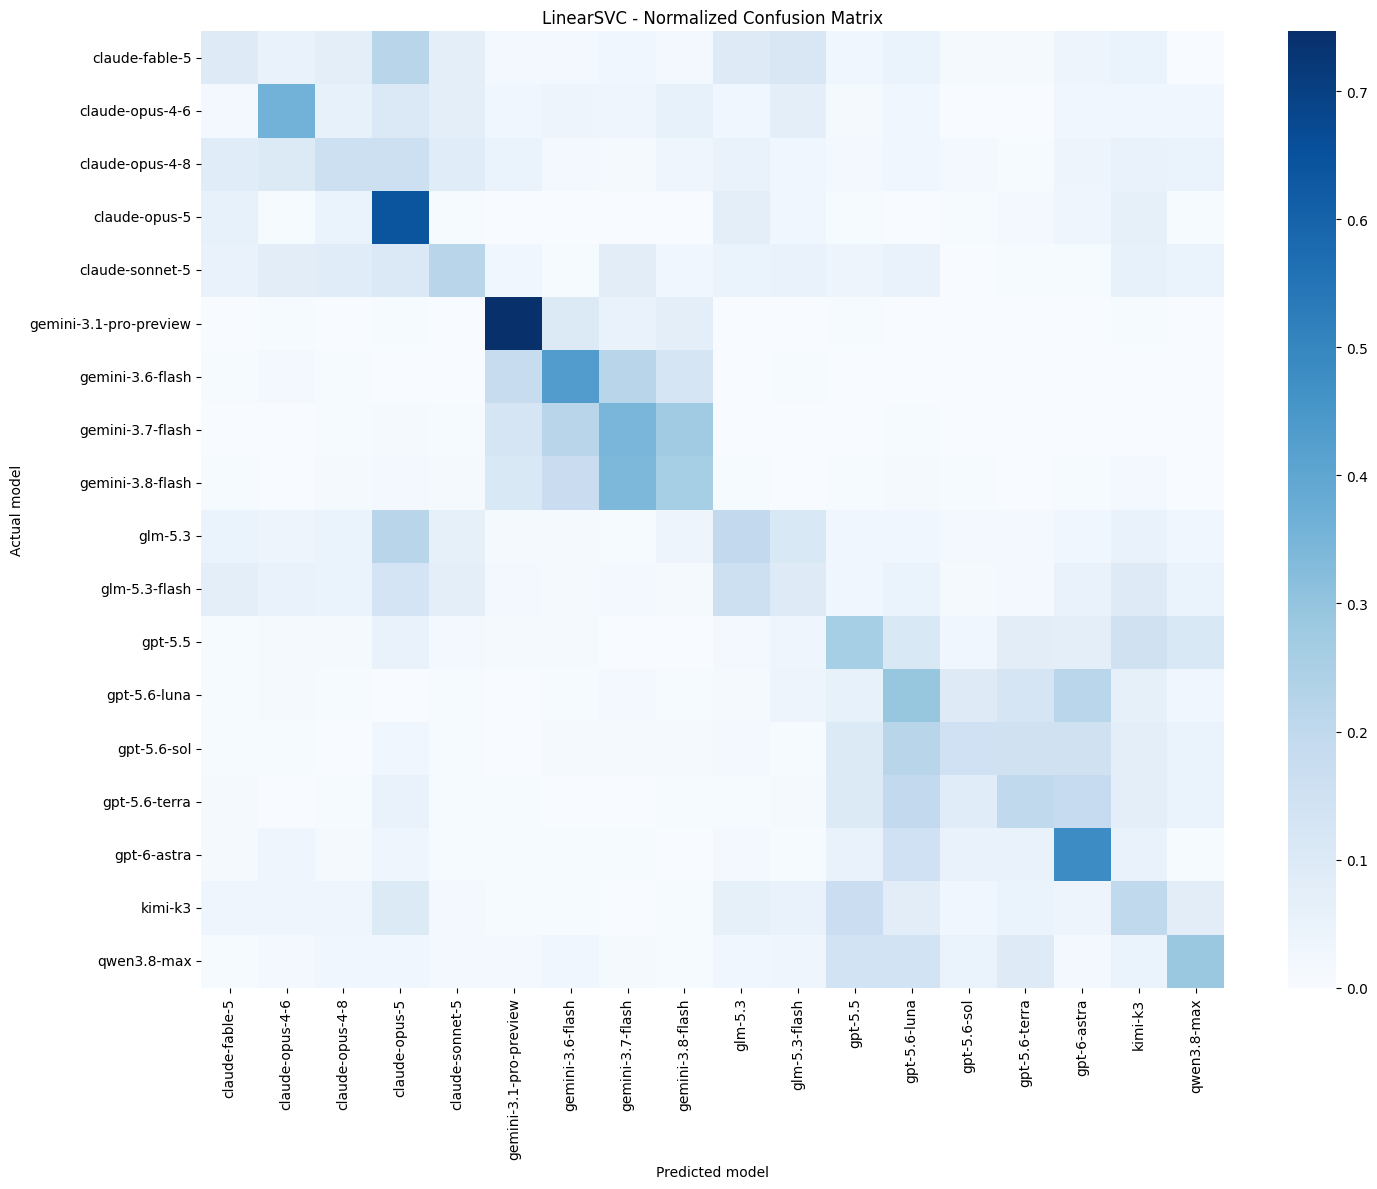

In [7]:
labels = sorted(y.unique())

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=labels,
    normalize="true"
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("LinearSVC - Normalized Confusion Matrix")
plt.xlabel("Predicted model")
plt.ylabel("Actual model")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Experiment with different C values

In [8]:
results = []

for C in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:

    model.set_params(classifier__C=C)

    fold_scores = []

    for train_idx, valid_idx in cv.split(X, y, groups=groups):

        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        predictions = model.predict(X.iloc[valid_idx])

        score = balanced_accuracy_score(
            y.iloc[valid_idx],
            predictions
        )

        fold_scores.append(score)

    results.append({
        "C": C,
        "mean_balanced_accuracy": np.mean(fold_scores),
        "std": np.std(fold_scores)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    "mean_balanced_accuracy",
    ascending=False
))

       C  mean_balanced_accuracy       std
2   0.50                0.306705  0.011710
1   0.10                0.302248  0.010326
3   1.00                0.301149  0.013606
4   2.00                0.300038  0.016568
5   5.00                0.299298  0.014757
6  10.00                0.298186  0.015365
0   0.01                0.280396  0.017957
